# 07 — Modelo económico de flipping

## Objetivo

Evaluar si las unidades que necesitan obra son oportunidades de flipping una vez
descontados **todos** los costos de la operación, y traducir el resultado en una
regla de decisión para el fondo de inversión (H3 y pregunta prescriptiva).

**Cómo está construido.**

- Los supuestos se leen del CSV, con su fuente, y los umbrales de `src/config.py`;
- el nivel de obra (liviana, media o integral) se asigna a cada aviso según la
  evidencia del texto, como define el README;
- se incluyen la contingencia de obra, el costo de oportunidad del capital y el
  factor de terminación en barrios de precio alto;
- toda la lógica está en `src/flipping.py`; la notebook solo la ejecuta e interpreta.

Con los supuestos con fuente, H3 no se sostiene (sección 10).

In [1]:
# Entorno: ubicar la raíz del repositorio (la carpeta que contiene src/)
import os
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (BASE_FEATURES, PROCESSED_DIR, SUPUESTOS_FLIPPING,
                        TIPO_CAMBIO_ARS_USD, TIPO_CAMBIO_FECHA, TIPO_CAMBIO_FUENTE,
                        MARGEN_MINIMO_PCT, PRESUPUESTO_MAX_USD,
                        DESCUENTO_NEGOCIABLE_PCT, MIN_COMPARABLES, UMBRAL_GAP)
from src import flipping as fl

sns.set_theme(style="whitegrid")

## 1. Universo evaluable

Se evalúan los avisos con precio, PER y superficie cubierta positivos. Por
construcción del PER (notebook 03), son las unidades clasificadas como
`Necesita_obra`.

In [2]:
df = pd.read_csv(BASE_FEATURES)
evaluable = (df["Precio_Valor"].gt(0) & df["PER_Base"].gt(0)
             & df["Superficie_Cubierta_m2"].gt(0))
df_flip = df.loc[evaluable].copy()

print("Avisos en la base:", len(df))
print("Evaluables para el modelo económico:", len(df_flip))
display(df_flip["Estado_Propiedad"].value_counts().to_frame("Avisos"))
display(df_flip[["Precio_Valor", "PER_Conservador", "PER_Base", "PER_Optimista",
                 "Superficie_Cubierta_m2", "PER_N_Comparables"]]
        .describe().T[["count", "50%", "min", "max"]].round(0))
print("PER base / precio publicado (mediana):",
      round((df_flip["PER_Base"] / df_flip["Precio_Valor"]).median(), 3))

Avisos en la base: 9499
Evaluables para el modelo económico: 428


,Avisos
Estado_Propiedad,
Necesita_obra,428


,count,50%,min,max
Precio_Valor,428.0,89000.0,27000.0,1150000.0
PER_Conservador,428.0,98787.0,26850.0,1163423.0
PER_Base,428.0,113066.0,30272.0,1388832.0
PER_Optimista,428.0,127894.0,34689.0,1665104.0
Superficie_Cubierta_m2,428.0,55.0,15.0,513.0
PER_N_Comparables,428.0,16.0,10.0,45.0


PER base / precio publicado (mediana): 1.231


El PER base es, en la mediana, un 23 % mayor que el precio publicado. Ese es el
"colchón" bruto que tiene que pagar la compra, la obra, la tenencia y la venta.

## 2. Supuestos de costo

Los supuestos están en `data/supuestos_flipping.csv`, por componente y escenario
y con su fuente. Los porcentajes se convierten a fracción al cargarlos.

In [3]:
tabla_supuestos = pd.read_csv(SUPUESTOS_FLIPPING)
display(tabla_supuestos[["componente", "unidad", "conservador", "base", "optimista", "fuente"]])
supuestos = fl.cargar_supuestos()
print("Tipo de cambio:", TIPO_CAMBIO_ARS_USD, "ARS/USD —", TIPO_CAMBIO_FUENTE, "—", TIPO_CAMBIO_FECHA)
print(f"Regla: margen mínimo {MARGEN_MINIMO_PCT} %, presupuesto USD {PRESUPUESTO_MAX_USD:,}, "
      f"descuento negociable {DESCUENTO_NEGOCIABLE_PCT} %, mínimo {MIN_COMPARABLES} comparables")

,componente,unidad,conservador,base,optimista,fuente
0,costo_obra_liviana,USD/m² cubierto,300,220,150,"Supuesto derivado: pintura ≈ USD 19–26/m² (Sui Color, vía La Nación 30/03/2026) + pisos + iluminación"
1,costo_obra_media,USD/m² cubierto,650,500,400,"Derivado de Reporte Inmobiliario (ene-2026), vía La Nación 30/03/2026: cocina integral USD 6.220 + baño integral USD 5.573 ≈ USD 11.800 por unidad (≈ USD 236/m² en 50 m²) + obra liviana en el resto"
2,costo_obra_integral,USD/m² cubierto,1300,1150,1000,"RenovArqui (feb-2026): ARS 1,5–1,83 M/m² + IVA, ≈ USD 1.070–1.310/m² a ARS 1.400. Cota superior de referencia: obra nueva USD 1.428/m² (APYMECO ene-2026, vía iProfesional)"
3,factor_terminacion_premium,multiplicador,1.3,1.2,1.0,Supuesto para sensibilidad (el costo por m² puede no ser comparable entre barrios)
4,contingencia,% del costo de obra,20,15,10,Rango del README (10–20 %); las fuentes consultadas no fijan un porcentaje
5,costos_compra,% del precio de compra,8.0,7.0,6.0,"Plato (2026), costos de escrituración CABA: sellos 1,75 % (comprador), escribano 1,2–1,5 % con IVA, certificados 0,3–0,5 %, registro 0,2–0,4 %; comisión inmobiliaria ≈ 3–4 % (supuesto)"
6,costos_venta,% del precio de venta,6.0,5.5,4.5,"Plato (2026), costos de escrituración CABA: sellos 1,75 % (vendedor); comisión inmobiliaria ≈ 3 % + IVA (supuesto)"
7,plazo_obra_liviana,meses,2.0,1.5,1.0,Supuesto (rango del README: 2–6 meses según nivel)
8,plazo_obra_media,meses,3.0,2.5,2.0,Supuesto (rango del README: 2–6 meses según nivel)
9,plazo_obra_integral,meses,6.0,5.0,4.0,RenovArqui (feb-2026): integral de 50–60 m² ≈ 4 meses sin demoras


Tipo de cambio: 1575.0 ARS/USD — Dólar MEP, venta (DolarHub, histórico) — 2026-11-02
Regla: margen mínimo 15 %, presupuesto USD 300,000, descuento negociable 10 %, mínimo 10 comparables


## 3. Nivel de obra de cada aviso

- **Integral:** el aviso dice "a reciclar" o "a refaccionar" (señal fuerte), o no
  hay evidencia clara (caso conservador).
- **Media:** solo hay señales débiles ("a actualizar", "a modernizar").

La obra liviana no se asigna desde el texto: ningún patrón la identifica de forma
confiable. Su efecto se mide en la sensibilidad (sección 7).

En los barrios del cuartil superior de USD/m² se aplica el factor de terminación
premium al costo de obra.

In [4]:
df_flip["Nivel_Obra"], df_flip["Evidencia_Obra"] = fl.asignar_nivel_obra(df_flip)
display(pd.crosstab(df_flip["Evidencia_Obra"], df_flip["Nivel_Obra"], margins=True))

premium = fl.barrios_premium(df)
print("Barrios con factor premium:", ", ".join(sorted(premium)))

Nivel_Obra,Integral,Media,All
Evidencia_Obra,,,
Señal débil,0,117,117
Señal fuerte,307,0,307
Sin evidencia,4,0,4
All,311,117,428


Barrios con factor premium: Belgrano, Chacarita, Coghlan, Colegiales, Nuñez, Palermo, Puerto Madero, Recoleta, Saavedra, Villa Devoto, Villa Ortuzar, Villa Urquiza


## 4. Rentabilidad por escenario

In [5]:
df_flip = fl.calcular_escenarios(df_flip, supuestos, premium)
display(fl.resumen_escenarios(df_flip).round(1))

componentes = pd.DataFrame({
    "Precio publicado": df_flip["Precio_Valor"],
    "Obra": df_flip["Costo_Obra_Base_USD"],
    "Tenencia": df_flip["Costo_Tenencia_Base_USD"],
    "Oportunidad": df_flip["Costo_Oportunidad_Base_USD"],
    "Inversión total": df_flip["Inversion_Total_Base_USD"],
    "PER base": df_flip["PER_Base"],
}).median().round(0).to_frame("Mediana USD (escenario base)")
display(componentes)

,Escenario,ROI_mediano_pct,Rentables,Rentables_pct,Con_ROI_≥_15%
0,Conservador,-53.0,0,0.0,0
1,Base,-38.8,2,0.5,0
2,Optimista,-19.3,62,14.5,16


,Mediana USD (escenario base)
Precio publicado,89000.0
Obra,63365.0
Tenencia,1250.0
Oportunidad,8299.0
Inversión total,169208.0
PER base,113066.0


En el escenario base, la mediana del costo de obra es comparable al precio de
compra. El PER no alcanza a cubrir esa inversión: el ROI mediano es fuertemente
negativo en los tres escenarios.

In [6]:
df_flip["Robustez_Economica"] = fl.clasificar_robustez(df_flip)
display(df_flip["Robustez_Economica"].value_counts().to_frame("Avisos"))
display(df_flip.groupby("Nivel_Obra")[["ROI_Conservador_pct", "ROI_Base_pct", "ROI_Optimista_pct"]]
        .median().round(1))

,Avisos
Robustez_Economica,
No rentable,366
Rentable solo en optimista,60
Rentable en base y optimista,2


,ROI_Conservador_pct,ROI_Base_pct,ROI_Optimista_pct
Nivel_Obra,,,
Integral,-55.3,-41.8,-22.6
Media,-42.5,-25.8,-3.2


## 5. ¿Cuánta obra paga el mercado?

Es la cota implícita del mercado que plantea el README. Para cada aviso se
calcula el costo de obra máximo por m² cubierto que deja un ROI de 0 en el
escenario base, comprando al precio publicado. Se compara con el costo base de
cada nivel de obra.

,Costo base USD/m²,Avisos que lo pagan
Liviana,220.0,132
Media,500.0,36
Integral,1150.0,1


Obra máxima pagable, mediana: 24 USD/m²


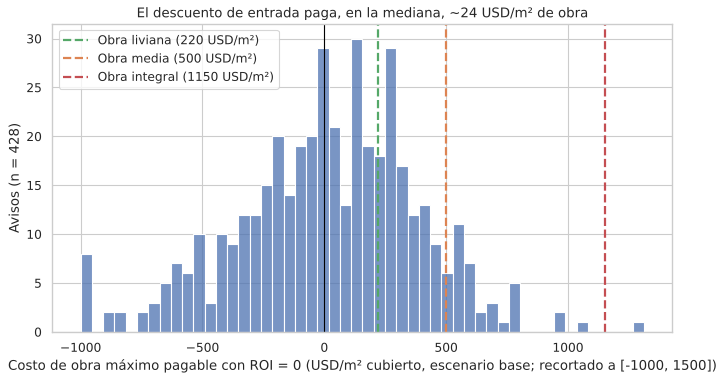

In [7]:
sb = supuestos["Base"]
meses = df_flip["Meses_Operacion_Base"]
k = sb["tasa_oportunidad"] * meses / 12
venta_neta = df_flip["PER_Base"] * (1 - sb["costos_venta"])
obra_max = (venta_neta / (1 + k) - df_flip["Precio_Valor"] * (1 + sb["costos_compra"])
            - df_flip["Expensas_USD_Mensuales"] * meses)
df_flip["Obra_Max_Pagable_USD_m2"] = obra_max / df_flip["Superficie_Cubierta_m2"] / (1 + sb["contingencia"])

niveles = {"Liviana": sb["costo_obra_liviana"], "Media": sb["costo_obra_media"],
           "Integral": sb["costo_obra_integral"]}
display(pd.DataFrame({
    "Costo base USD/m²": niveles,
    "Avisos que lo pagan": {n: int((df_flip["Obra_Max_Pagable_USD_m2"] >= c).sum()) for n, c in niveles.items()},
}))
print("Obra máxima pagable, mediana:", round(df_flip["Obra_Max_Pagable_USD_m2"].median()), "USD/m²")

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df_flip["Obra_Max_Pagable_USD_m2"].clip(-1000, 1500), bins=50, ax=ax, color="#4C72B0")
for (n, c), col in zip(niveles.items(), ["#55A868", "#DD8452", "#C44E52"]):
    ax.axvline(c, color=col, ls="--", lw=2, label=f"Obra {n.lower()} ({c:.0f} USD/m²)")
ax.axvline(0, color="black", lw=1)
ax.set(title=f"El descuento de entrada paga, en la mediana, ~{df_flip['Obra_Max_Pagable_USD_m2'].median():.0f} USD/m² de obra",
       xlabel="Costo de obra máximo pagable con ROI = 0 (USD/m² cubierto, escenario base; recortado a [-1000, 1500])",
       ylabel=f"Avisos (n = {len(df_flip)})")
ax.legend()
plt.show()

**Lectura.** En la mediana, el descuento con que se publican las unidades a
reciclar alcanza para pagar unos pocos dólares por m² de obra. Solo una minoría
paga una obra liviana, y prácticamente ninguna, una integral. El descuento por
estado que se midió en H1 (≈ 17 %) es real, pero alcanza para cubrir los costos
de transacción y de tenencia, no la obra.

## 6. Regla de decisión y alertas

Para cada aviso se calcula el **precio máximo de oferta**: el mayor precio de
compra al que se cumplen **a la vez** las tres condiciones económicas de la
regla del README. Es el menor de tres techos:

| Condición | Techo de precio |
|---|---|
| ROI base ≥ margen mínimo (15 %) | `Precio_Max_Oferta_Base_USD` |
| ROI conservador ≥ 0 | `Precio_Max_ROI_Conservador_0_USD` |
| Gap de subvaluación ≥ umbral (25 %) | `Precio_Esperado × 0,75` |

La columna `Restriccion_Activa` indica qué condición fija el precio. Después se
recalcula el modelo completo a ese precio (`fl.verificar_oferta`) para comprobar
que la regla hace lo que declara, y el presupuesto se controla con la inversión
a ese precio.

| Decisión | Condición |
|---|---|
| Comprar al precio publicado | El precio publicado ya cumple las tres condiciones, inversión ≤ presupuesto, comparables ≥ mínimo, sin alertas |
| Ofertar con descuento | Igual, pero hace falta un descuento ≤ el negociable (10 %) |
| Revisar manualmente | Cerraría al precio publicado o con descuento, pero tiene alertas |
| Descartar | El resto |

Las alertas marcan resultados poco confiables: uso no residencial, superficie
mayor a 200 m², ROI base mayor a 80 %, PER de nivel 4, señal de estado
contradictoria y expensas imputadas.


In [8]:
alertas = fl.alertas(df_flip)
df_flip = pd.concat([df_flip.drop(columns=alertas.columns, errors="ignore"), alertas], axis=1)
df_flip["Cantidad_Alertas"] = alertas.sum(axis=1)

# Precio máximo de oferta: menor de los tres techos, y verificación a ese precio
df_flip = pd.concat([df_flip, fl.precio_max_oferta(df_flip)], axis=1)
df_flip = pd.concat([df_flip, fl.verificar_oferta(df_flip, supuestos, premium)], axis=1)
df_flip["Decision"] = fl.aplicar_regla(df_flip)

display(alertas.sum().to_frame("Avisos con la alerta"))
display(df_flip["Restriccion_Activa"].value_counts().to_frame("Avisos (condición que fija el precio)"))
display(df_flip["Decision"].value_counts().to_frame("Avisos"))


,Avisos con la alerta
Alerta_Uso_No_Residencial,98
Alerta_Superficie_Alta,14
Alerta_ROI_Extremo,0
Alerta_PER_Nivel_4,55
Alerta_Senal_Contradictoria,66
Alerta_Expensas_Imputadas,27


,Avisos (condición que fija el precio)
Restriccion_Activa,
ROI conservador ≥ 0,428


,Avisos
Decision,
Descartar,428


In [9]:
# Al precio ofertado se cumplen las tres condiciones, en todos los avisos
assert (df_flip["ROI_Base_Oferta_pct"] >= MARGEN_MINIMO_PCT - 1e-6).all()
assert (df_flip["ROI_Conservador_Oferta_pct"] >= -1e-6).all()
assert (df_flip["Gap_Oferta_pct"] >= UMBRAL_GAP - 1e-6).all()

# Ejemplo: si el techo solo exigiera el margen en el escenario base, el aviso 550445
# quedaría con ROI conservador negativo al precio ofertado
caso = df_flip.loc[df_flip["ID"] == 550445, [
    "ID", "Precio_Valor", "Precio_Max_Oferta_Base_USD", "Precio_Max_ROI_Conservador_0_USD",
    "Precio_Max_Oferta_USD", "Restriccion_Activa", "ROI_Conservador_Oferta_pct",
    "ROI_Base_Oferta_pct", "Descuento_Requerido_pct", "Decision"]]
display(caso.T.round(1))


,8023
ID,550445
Precio_Valor,99900.0
Precio_Max_Oferta_Base_USD,95410.640441
Precio_Max_ROI_Conservador_0_USD,80542.222552
Precio_Max_Oferta_USD,80542.222552
Restriccion_Activa,ROI conservador ≥ 0
ROI_Conservador_Oferta_pct,0.0
ROI_Base_Oferta_pct,31.395829
Descuento_Requerido_pct,19.377155
Decision,Descartar


**Lectura.** Si el precio máximo de oferta solo garantizara el margen en el
escenario base, para el aviso 550445 (USD 99.900) sería USD 95.411, y a ese
precio el ROI conservador seguiría en −11,4 %, aunque la regla exige que no sea
negativo. Ahora el techo lo fija la condición
que más restringe; en casi todos los avisos es el ROI conservador ≥ 0, no el
margen base. Las tres condiciones se verifican recalculando el modelo al precio
ofertado (las aserciones de arriba fallarían si no se cumplieran).


## 7. Sensibilidad

El resultado depende de supuestos inciertos. Se recalcula el modelo sobre los
428 avisos variando de a un supuesto por vez:

- **Nivel de obra:** el nivel se infiere del texto; se evalúa qué pasa si todas
  fueran livianas, medias o integrales.
- **Descuento de negociación:** el precio de cierre suele ser menor que el
  publicado (el PER también surge de precios publicados, por lo que el efecto
  real es menor que el que muestra la tabla).
- **Tipo de cambio:** ±20 %, afecta solo a las expensas.
- **Margen mínimo exigido.**

In [10]:
filas = []
def registrar(dimension, valor, d):
    filas.append({"Dimensión": dimension, "Valor": valor,
                  "ROI>0 conservador": int((d["ROI_Conservador_pct"] > 0).sum()),
                  "ROI>0 base": int((d["ROI_Base_pct"] > 0).sum()),
                  "ROI>0 optimista": int((d["ROI_Optimista_pct"] > 0).sum()),
                  f"ROI base ≥ {MARGEN_MINIMO_PCT} %": int((d["ROI_Base_pct"] >= MARGEN_MINIMO_PCT).sum()),
                  "ROI base mediano (%)": round(d["ROI_Base_pct"].median(), 1)})

registrar("Referencia", "Nivel asignado, sin descuento", df_flip)
for nivel in ["Liviana", "Media", "Integral"]:
    registrar("Nivel de obra", f"Todas {nivel.lower()}",
              fl.calcular_escenarios(df_flip.assign(Nivel_Obra=nivel), supuestos, premium))
for desc in [0.05, 0.10, 0.15, 0.20]:
    registrar("Descuento de negociación", f"{desc:.0%}",
              fl.calcular_escenarios(df_flip, supuestos, premium, descuento_compra=desc))
for factor in [0.8, 1.2]:
    registrar("Tipo de cambio", f"{factor:.0%} del de referencia",
              fl.calcular_escenarios(df_flip, supuestos, premium, tipo_cambio=TIPO_CAMBIO_ARS_USD * factor))
sensibilidad = pd.DataFrame(filas)
display(sensibilidad)

margenes = pd.DataFrame({"Margen mínimo (%)": [0, 5, 10, 15, 20, 25]})
margenes["Avisos que lo alcanzan (base)"] = [int((df_flip["ROI_Base_pct"] >= m).sum()) for m in margenes["Margen mínimo (%)"]]
margenes["Con descuento ≤ 10 % (base)"] = [
    int((fl.calcular_escenarios(df_flip, supuestos, premium, descuento_compra=0.10)["ROI_Base_pct"] >= m).sum())
    for m in margenes["Margen mínimo (%)"]]
display(margenes)

,Dimensión,Valor,ROI>0 conservador,ROI>0 base,ROI>0 optimista,ROI base ≥ 15 %,ROI base mediano (%)
0,Referencia,"Nivel asignado, sin descuento",0,2,62,0,-38.8
1,Nivel de obra,Todas liviana,16,137,311,51,-9.5
2,Nivel de obra,Todas media,0,36,202,7,-23.0
3,Nivel de obra,Todas integral,0,0,20,0,-42.5
4,Descuento de negociación,5%,0,4,84,1,-37.0
5,Descuento de negociación,10%,0,6,104,1,-35.1
6,Descuento de negociación,15%,0,10,122,1,-32.9
7,Descuento de negociación,20%,1,27,148,3,-30.5
8,Tipo de cambio,80% del de referencia,0,2,61,0,-39.0
9,Tipo de cambio,120% del de referencia,0,2,62,0,-38.7


,Margen mínimo (%),Avisos que lo alcanzan (base),Con descuento ≤ 10 % (base)
0,0,2,6
1,5,1,3
2,10,1,1
3,15,0,1
4,20,0,1
5,25,0,0


**Lectura.**

- El supuesto que más pesa es el **nivel de obra**. Si todas las unidades
  requirieran solo una obra liviana, una parte relevante sería rentable en el
  escenario base. Con obra integral no lo es ninguna. Por eso, la variable que
  más conviene verificar antes de ofertar es el alcance real de la obra (visita
  técnica).
- La **negociación** mejora el resultado, pero no lo cambia: con un 10 % de
  descuento, muy pocas unidades alcanzan el margen mínimo en el escenario base.
- El **tipo de cambio** casi no influye, porque solo afecta a las expensas.

## 8. Ranking de seguimiento

Se ordena a los 428 avisos según el descuento que necesitarían para cumplir
todas las condiciones económicas de la regla (sección 6). Los primeros puestos no son recomendaciones
de compra: son las unidades que conviene seguir (precio, visita técnica,
cotización de obra), porque son las más cercanas a cerrar.

In [11]:
df_flip = df_flip.sort_values("Descuento_Requerido_pct").reset_index(drop=True)
df_flip["Ranking_Priorizado"] = np.arange(1, len(df_flip) + 1)
df_flip["Prioridad_Analisis"] = df_flip["Decision"]

cols = ["Ranking_Priorizado", "ID", "Barrio_Oficial", "Precio_Valor", "Superficie_Cubierta_m2",
        "Nivel_Obra", "Inversion_Total_Base_USD", "ROI_Conservador_pct", "ROI_Base_pct",
        "ROI_Optimista_pct", "Precio_Max_Oferta_USD", "Descuento_Requerido_pct",
        "Restriccion_Activa", "ROI_Conservador_Oferta_pct", "ROI_Base_Oferta_pct",
        "PER_N_Comparables", "Cantidad_Alertas", "Decision"]
display(df_flip[cols].head(15).round(1))

seguimiento = df_flip["Descuento_Requerido_pct"] <= 2 * DESCUENTO_NEGOCIABLE_PCT
print(f"Avisos que cumplirían la regla con un descuento ≤ {2 * DESCUENTO_NEGOCIABLE_PCT} %:",
      int(seguimiento.sum()))
for tope in [10, 20, 30]:
    print(f"  con descuento ≤ {tope} %:", int((df_flip["Descuento_Requerido_pct"] <= tope).sum()),
          f"(solo margen base: {int((df_flip['Descuento_Requerido_Base_pct'] <= tope).sum())})")


,Ranking_Priorizado,ID,Barrio_Oficial,Precio_Valor,Superficie_Cubierta_m2,Nivel_Obra,Inversion_Total_Base_USD,ROI_Conservador_pct,ROI_Base_pct,ROI_Optimista_pct,Precio_Max_Oferta_USD,Descuento_Requerido_pct,Restriccion_Activa,ROI_Conservador_Oferta_pct,ROI_Base_Oferta_pct,PER_N_Comparables,Cantidad_Alertas,Decision
0,1,550445,Palermo,99900.0,36.0,Media,137922.4,-14.4,10.8,47.2,80542.2,19.4,ROI conservador ≥ 0,0.0,31.4,19.0,1,Descartar
1,2,511218,Belgrano,249000.0,141.6,Media,382163.1,-20.0,-2.9,19.9,172099.2,30.9,ROI conservador ≥ 0,0.0,25.3,14.0,0,Descartar
2,3,619765,Belgrano,270000.0,116.5,Media,387258.9,-25.7,-11.7,6.9,171847.9,36.4,ROI conservador ≥ 0,0.0,23.2,14.0,0,Descartar
3,4,575368,Caballito,55000.0,29.0,Media,79860.1,-28.9,-14.8,-2.1,32625.8,40.7,ROI conservador ≥ 0,0.0,23.9,12.0,0,Descartar
4,5,637044,Caballito,59900.0,44.3,Media,94511.0,-26.7,-11.9,16.4,34980.2,41.6,ROI conservador ≥ 0,0.0,24.9,14.0,1,Descartar
5,6,391982,Palermo,63000.0,37.3,Media,97863.7,-26.8,0.9,27.6,36433.0,42.2,ROI conservador ≥ 0,0.0,44.7,22.0,1,Descartar
6,7,643926,Villa Crespo,85000.0,49.5,Media,125618.8,-29.5,-16.3,1.9,49003.6,42.3,ROI conservador ≥ 0,0.0,23.0,12.0,0,Descartar
7,8,609473,Caballito,82000.0,49.6,Media,121453.1,-31.0,-12.0,3.5,45323.8,44.7,ROI conservador ≥ 0,-0.0,32.7,18.0,0,Descartar
8,9,647627,Recoleta,850000.0,513.0,Media,1322630.4,-30.0,-0.8,38.4,449101.1,47.2,ROI conservador ≥ 0,0.0,49.9,19.0,4,Descartar
9,10,584969,Almagro,129000.0,86.0,Media,197360.8,-31.5,-18.6,-5.0,68042.3,47.3,ROI conservador ≥ 0,0.0,24.2,14.0,0,Descartar


Avisos que cumplirían la regla con un descuento ≤ 20 %: 1
  con descuento ≤ 10 %: 0 (solo margen base: 1)
  con descuento ≤ 20 %: 1 (solo margen base: 3)
  con descuento ≤ 30 %: 1 (solo margen base: 7)


## 9. Exportación y verificación

In [12]:
ruta_base = PROCESSED_DIR / "flipping_modelo_economico.csv"
ruta_ranking = PROCESSED_DIR / "flipping_ranking_priorizado.csv"
cols_ranking = cols + ["Robustez_Economica", "Prioridad_Analisis", "Evidencia_Obra",
                       "Barrio_Premium", "PER_Base", "PER_Nivel", "Link", "Titulo"] + list(alertas.columns)
df_flip.to_csv(ruta_base, index=False, encoding="utf-8-sig")
df_flip[cols_ranking].to_csv(ruta_ranking, index=False, encoding="utf-8-sig")

base = pd.read_csv(ruta_base)
ranking = pd.read_csv(ruta_ranking)
assert len(base) == len(ranking) == evaluable.sum()
assert ranking["ID"].is_unique
assert ranking["Descuento_Requerido_pct"].is_monotonic_increasing
comprar = ranking["Decision"] == "Comprar al precio publicado"
assert (ranking.loc[comprar, "ROI_Base_pct"] >= MARGEN_MINIMO_PCT).all()
ok = ranking["Decision"] != "Descartar"
assert (ranking.loc[ok, "ROI_Conservador_Oferta_pct"] >= -1e-6).all()
print("Exportados:", ruta_base.name, len(base), "filas;", ruta_ranking.name, len(ranking), "filas")

Exportados: flipping_modelo_economico.csv 428 filas; flipping_ranking_priorizado.csv 428 filas


## 10. Conclusiones

**H3 no se sostiene con los supuestos de costo con fuente.** Ninguna de las 428
unidades que necesitan obra es rentable en el escenario conservador, y solo una
fracción mínima lo es en el escenario base. La razón es estructural: el
descuento con que se publican las unidades a reciclar (PER ≈ 1,23 veces el
precio) cubre los costos de compra, venta y tenencia, pero no el de una obra
media o integral. En la mediana, el mercado paga unos pocos USD/m² de obra,
mientras que una obra media cuesta unos 500 USD/m² y una integral, unos 1.150.

**Implicancias para el fondo.**

1. Comprar unidades a reciclar al precio publicado para hacer flipping no es una
   estrategia rentable en general. El mercado ya descuenta el estado, pero no lo
   suficiente.
2. La oportunidad existe solo en casos puntuales: obras livianas o precios muy
   por debajo de lo publicado. La herramienta útil no es un ranking de compras,
   sino el **precio máximo de oferta** de cada unidad: el mayor precio al que se
   cumplen el margen base, el ROI conservador no negativo y el gap mínimo. El
   fondo puede ofertar ese valor y comprar solo si el vendedor lo acepta. Al
   exigir también el escenario conservador, el descuento necesario sube: ninguna
   unidad cumple la regla con un descuento de hasta 10 % y solo una con hasta 30 %.
3. Antes de cualquier oferta hay que verificar el **alcance real de la obra**,
   porque es el supuesto que más mueve el resultado.

**Limitaciones.**

- Los costos por m² son supuestos con fuente secundaria (prensa y cámaras), no
  cotizaciones propias. Una cotización real por debajo de los valores usados
  mejoraría el resultado.
- El PER se estima con comparables "buen estado o reciclada". Una unidad recién
  reciclada de forma integral puede valer más que una en buen estado; el
  escenario optimista (P75) aproxima ese caso.
- No se modelan impuestos (cedular), financiamiento ni la brecha entre precio
  publicado y de cierre en la reventa.
- El nivel de obra surge del texto del aviso, no de una inspección.